# Causal Lab — randomized evidence and honest policy evaluation

**Decision question.** Does randomized assignment create incremental outcomes, and does targeting improve constrained policy value without confusing prediction with treatment effect?

This executed notebook is the reviewer-facing analytical layer. Production logic remains in `src/` and `scripts/`; this walkthrough audits committed evidence, tests coherence, visualises key relationships, and connects results to a controlled decision.

## Research protocol

1. Resolve the repository root without machine-specific paths.
2. Verify every evidence file before interpretation.
3. Audit row counts, missingness, duplicates, and numerical ranges.
4. Read locked outputs rather than silently refitting on review data.
5. Separate measured results, scenario assumptions, and decision claims.
6. End with limitations and an explicit promotion boundary.

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")
plt.style.use("seaborn-v0_8-whitegrid")

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
print(f"Repository: {ROOT.name}")

Matplotlib is building the font cache; this may take a moment.


Repository: causal-experimentation-lab


In [2]:
def load_artifact(relative_path):
    path = ROOT / relative_path
    if not path.exists():
        raise FileNotFoundError(relative_path)
    suffix = path.suffix.lower()
    if suffix == ".csv":
        return pd.read_csv(path)
    if suffix == ".json":
        return json.loads(path.read_text(encoding="utf-8"))
    if suffix in {".md", ".txt"}:
        return path.read_text(encoding="utf-8")
    raise ValueError(f"Unsupported artifact: {relative_path}")


def audit_frame(frame, name):
    numeric = frame.select_dtypes(include="number")
    summary = pd.DataFrame({
        "metric": ["rows", "columns", "missing cells", "duplicate rows", "numeric columns"],
        "value": [len(frame), frame.shape[1], int(frame.isna().sum().sum()),
                  int(frame.duplicated().sum()), numeric.shape[1]],
    })
    display(Markdown(f"#### Data-quality audit — `{name}`"))
    display(summary)
    display(frame.head(8))
    if not numeric.empty:
        display(numeric.describe().T[["count", "mean", "std", "min", "50%", "max"]])


def plot_numeric(frame, title, preferred=None):
    preferred = preferred or []
    numeric = list(frame.select_dtypes(include="number").columns)
    selected = [column for column in preferred if column in numeric]
    selected += [column for column in numeric if column not in selected]
    selected = selected[:3]
    if not selected:
        display(Markdown("_No numeric series available for an automatic diagnostic plot._"))
        return
    view = frame[selected].replace([np.inf, -np.inf], np.nan).dropna(how="all")
    if view.empty:
        display(Markdown("_Numeric series are empty after cleaning._"))
        return
    ax = view.reset_index(drop=True).plot(figsize=(10, 4), linewidth=1.8)
    ax.set_title(title)
    ax.set_xlabel("Observation / ordered bucket")
    ax.set_ylabel("Reported value")
    plt.tight_layout()
    plt.show()


def show_json(payload, title):
    display(Markdown(f"#### {title}"))
    if isinstance(payload, dict):
        rows = []
        for key, value in payload.items():
            if isinstance(value, (dict, list)):
                value = json.dumps(value, ensure_ascii=False)
            rows.append({"field": key, "value": value})
        display(pd.DataFrame(rows))
    else:
        display(pd.DataFrame(payload))

## 1. Evidence receipt and reproducibility boundary

In [3]:
expected = ['reports/generated/policy_curve.csv', 'reports/generated/uplift_deciles.csv', 'reports/feature_provenance.csv', 'reports/generated/ate_results.json', 'reports/generated/data_audit.json', 'reports/generated/uplift_policy_results.json', 'reports/figures/01_itt_effects.png', 'reports/figures/02_covariate_balance.png', 'reports/figures/03_holdout_uplift_deciles.png', 'reports/figures/04_policy_value.png']
receipt = pd.DataFrame({
    "artifact": expected,
    "exists": [(ROOT / item).exists() for item in expected],
    "bytes": [(ROOT / item).stat().st_size if (ROOT / item).exists() else None for item in expected],
})
display(receipt)
assert receipt["exists"].all(), "A committed evidence artifact is missing"

,artifact,exists,bytes
0,reports/generated/policy_curve.csv,True,1053
1,reports/generated/uplift_deciles.csv,True,820
2,reports/feature_provenance.csv,True,5537
3,reports/generated/ate_results.json,True,1509
4,reports/generated/data_audit.json,True,3266
5,reports/generated/uplift_policy_results.json,True,6183
6,reports/figures/01_itt_effects.png,True,30873
7,reports/figures/02_covariate_balance.png,True,43263
8,reports/figures/03_holdout_uplift_deciles.png,True,57857
9,reports/figures/04_policy_value.png,True,106229


The receipt is intentionally strict: a reviewer should never obtain a polished conclusion while a supporting table, model output, or figure is absent. Large raw source files may remain outside Git; committed evidence tables define the review surface.

## 2. Evidence table — `reports/generated/policy_curve.csv`

In [4]:
frame_1 = load_artifact('reports/generated/policy_curve.csv')
audit_frame(frame_1, 'reports/generated/policy_curve.csv')

#### Data-quality audit — `reports/generated/policy_curve.csv`

,metric,value
0,rows,10
1,columns,6
2,missing cells,0
3,duplicate rows,0
4,numeric columns,6


,target_fraction,subgroup_ate,standard_error,n,incremental_visits_per_100k_targeted,incremental_visits_per_100k_eligible
0,0.1000,0.0854,0.0024,300000,"8,536.2092",853.6209
1,0.2000,0.0475,0.0014,600000,"4,750.0654",950.0131
2,0.3000,0.0321,0.0009,900000,"3,213.6819",964.1046
3,0.4000,0.0242,0.0007,1200000,"2,420.3922",968.1569
4,0.5000,0.0195,0.0006,1500000,"1,950.7712",975.3856
5,0.6000,0.0163,0.0005,1800000,"1,633.5076",980.1046
6,0.7000,0.0140,0.0004,2100000,"1,401.4379",981.0065
7,0.8000,0.0123,0.0004,2400000,"1,226.9608",981.5686


,count,mean,std,min,50%,max
target_fraction,10.0000,0.5500,0.3028,0.1000,0.5500,1.0000
subgroup_ate,10.0000,0.0272,0.0235,0.0102,0.0179,0.0854
standard_error,10.0000,0.0008,0.0007,0.0003,0.0005,0.0024
n,10.0000,"1,650,000.0000","908,295.1062","300,000.0000","1,650,000.0000","3,000,000.0000"
incremental_visits_per_100k_targeted,10.0000,"2,723.9810","2,347.1175","1,016.3268","1,792.1394","8,536.2092"
incremental_visits_per_100k_eligible,10.0000,965.1699,42.7017,853.6209,977.7451,"1,016.3268"


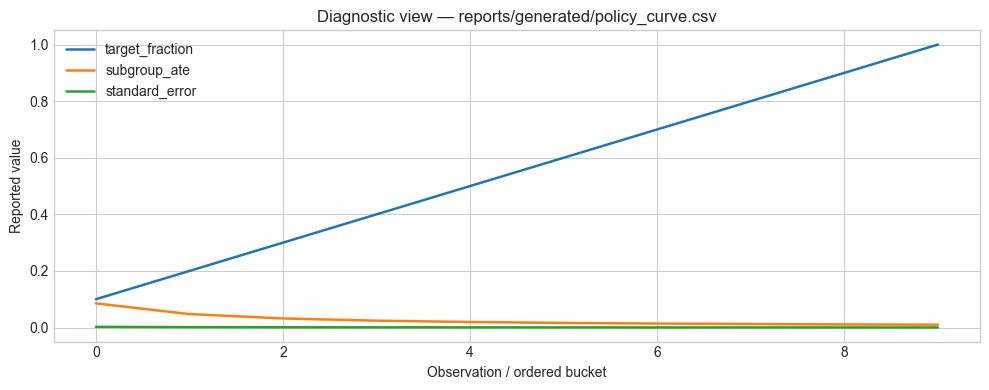

In [5]:
plot_numeric(frame_1, 'Diagnostic view — reports/generated/policy_curve.csv')

## 3. Evidence table — `reports/generated/uplift_deciles.csv`

In [6]:
frame_2 = load_artifact('reports/generated/uplift_deciles.csv')
audit_frame(frame_2, 'reports/generated/uplift_deciles.csv')

#### Data-quality audit — `reports/generated/uplift_deciles.csv`

,metric,value
0,rows,10
1,columns,5
2,missing cells,0
3,duplicate rows,0
4,numeric columns,5


,decile,n,mean_predicted_uplift,ipw_observed_effect,standard_error
0,10,300000,0.0713,0.0853,0.0024
1,9,300000,0.0100,0.0097,0.0013
2,8,300000,0.0023,0.0014,0.0006
3,7,300000,0.0009,0.0004,0.0004
4,6,300000,0.0005,0.0007,0.0002
5,5,300000,0.0003,0.0005,0.0002
6,4,300000,0.0002,0.0001,0.0002
7,3,300000,0.0001,0.0001,0.0002


,count,mean,std,min,50%,max
decile,10.0000,5.5000,3.0277,1.0000,5.5000,10.0000
n,10.0000,"300,000.0000",0.0000,"300,000.0000","300,000.0000","300,000.0000"
mean_predicted_uplift,10.0000,0.0078,0.0227,-0.0074,0.0004,0.0713
ipw_observed_effect,10.0000,0.0102,0.0266,-0.0000,0.0006,0.0853
standard_error,10.0000,0.0007,0.0007,0.0002,0.0004,0.0024


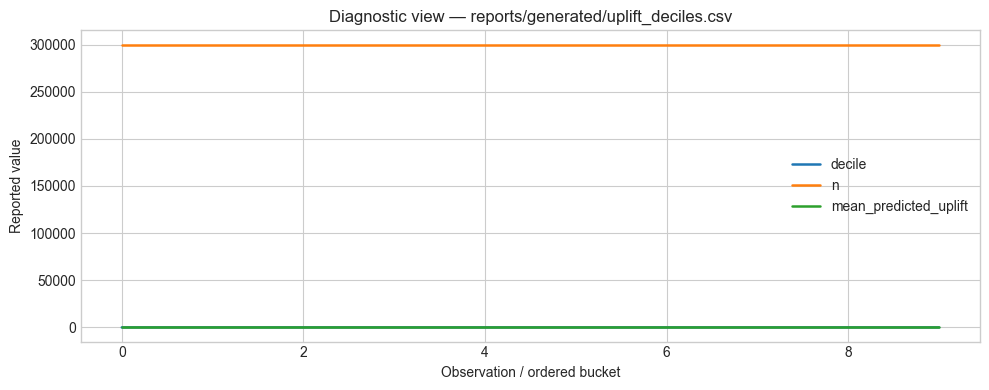

In [7]:
plot_numeric(frame_2, 'Diagnostic view — reports/generated/uplift_deciles.csv')

## 4. Evidence table — `reports/feature_provenance.csv`

In [8]:
frame_3 = load_artifact('reports/feature_provenance.csv')
audit_frame(frame_3, 'reports/feature_provenance.csv')

#### Data-quality audit — `reports/feature_provenance.csv`

,metric,value
0,rows,13
1,columns,14
2,missing cells,13
3,duplicate rows,0
4,numeric columns,1


,feature_name,feature_family,raw_source,grain,transformation,observation_cutoff,available_at_decision,fit_partition,missing_treatment,model_role,exclusion_reason,leakage_risk,proxy_or_fairness_risk,validation
0,f0,pre-treatment covariate,Criteo uplift source column f0,randomized unit,No invented semantic transformation; numeric v...,Measured before randomized assignment,yes,none,native numeric; source audit reports missingness,T-learner outcome model,NaN,low: pre-treatment source covariate,anonymous meaning prevents subgroup fairness i...,arm balance SMD and holdout-only uplift evalua...
1,f1,pre-treatment covariate,Criteo uplift source column f1,randomized unit,No invented semantic transformation; numeric v...,Measured before randomized assignment,yes,none,native numeric; source audit reports missingness,T-learner outcome model,NaN,low: pre-treatment source covariate,anonymous meaning prevents subgroup fairness i...,arm balance SMD and holdout-only uplift evalua...
2,f2,pre-treatment covariate,Criteo uplift source column f2,randomized unit,No invented semantic transformation; numeric v...,Measured before randomized assignment,yes,none,native numeric; source audit reports missingness,T-learner outcome model,NaN,low: pre-treatment source covariate,anonymous meaning prevents subgroup fairness i...,arm balance SMD and holdout-only uplift evalua...
3,f3,pre-treatment covariate,Criteo uplift source column f3,randomized unit,No invented semantic transformation; numeric v...,Measured before randomized assignment,yes,none,native numeric; source audit reports missingness,T-learner outcome model,NaN,low: pre-treatment source covariate,anonymous meaning prevents subgroup fairness i...,arm balance SMD and holdout-only uplift evalua...
4,f4,pre-treatment covariate,Criteo uplift source column f4,randomized unit,No invented semantic transformation; numeric v...,Measured before randomized assignment,yes,none,native numeric; source audit reports missingness,T-learner outcome model,NaN,low: pre-treatment source covariate,anonymous meaning prevents subgroup fairness i...,arm balance SMD and holdout-only uplift evalua...
5,f5,pre-treatment covariate,Criteo uplift source column f5,randomized unit,No invented semantic transformation; numeric v...,Measured before randomized assignment,yes,none,native numeric; source audit reports missingness,T-learner outcome model,NaN,low: pre-treatment source covariate,anonymous meaning prevents subgroup fairness i...,arm balance SMD and holdout-only uplift evalua...
6,f6,pre-treatment covariate,Criteo uplift source column f6,randomized unit,No invented semantic transformation; numeric v...,Measured before randomized assignment,yes,none,native numeric; source audit reports missingness,T-learner outcome model,NaN,low: pre-treatment source covariate,anonymous meaning prevents subgroup fairness i...,arm balance SMD and holdout-only uplift evalua...
7,f7,pre-treatment covariate,Criteo uplift source column f7,randomized unit,No invented semantic transformation; numeric v...,Measured before randomized assignment,yes,none,native numeric; source audit reports missingness,T-learner outcome model,NaN,low: pre-treatment source covariate,anonymous meaning prevents subgroup fairness i...,arm balance SMD and holdout-only uplift evalua...


,count,mean,std,min,50%,max
exclusion_reason,0.0000,NaN,NaN,NaN,NaN,NaN


In [9]:
plot_numeric(frame_3, 'Diagnostic view — reports/feature_provenance.csv')

_Numeric series are empty after cleaning._

## 5. Locked decision object — `reports/generated/ate_results.json`

In [10]:
payload = load_artifact('reports/generated/ate_results.json')
show_json(payload, 'reports/generated/ate_results.json')

#### reports/generated/ate_results.json

,field,value
0,conversion,"{""absolute_effect"": 0.0011518730521316279, ""ci..."
1,exposure_first_stage,0.0360
2,interpretation,"{""itt"": ""Primary causal estimate: effect of as..."
3,iv_complier_effect,"{""conversion"": 0.031963863885825596, ""visit"": ..."
4,visit,"{""absolute_effect"": 0.010342403129198284, ""ci_..."


## 6. Locked decision object — `reports/generated/data_audit.json`

In [11]:
payload = load_artifact('reports/generated/data_audit.json')
show_json(payload, 'reports/generated/data_audit.json')

#### reports/generated/data_audit.json

,field,value
0,covariate_balance,"[{""control_mean"": 19.651704714722086, ""control..."
1,max_absolute_smd,0.0488
2,source,Criteo Uplift Prediction Dataset v2.1 (corrected)
3,srm,"{""chi_square"": 1.817775848947767e-06, ""expecte..."
4,summary,"{""control_exposed"": 0, ""conversion_rate"": 0.00..."


## 7. Locked decision object — `reports/generated/uplift_policy_results.json`

In [12]:
payload = load_artifact('reports/generated/uplift_policy_results.json')
show_json(payload, 'reports/generated/uplift_policy_results.json')

#### reports/generated/uplift_policy_results.json

,field,value
0,deciles,"[{""decile"": 10, ""ipw_observed_effect"": 0.08533..."
1,diagnostics,"{""cross_fitted_conversion_dr_ate"": 0.000968771..."
2,policy_curve,"[{""incremental_visits_per_100k_eligible"": 853...."


## Visual evidence

![01_itt_effects](../reports/figures/01_itt_effects.png)

![02_covariate_balance](../reports/figures/02_covariate_balance.png)

![03_holdout_uplift_deciles](../reports/figures/03_holdout_uplift_deciles.png)

![04_policy_value](../reports/figures/04_policy_value.png)

## Decision

**Retain broad treatment when marginal treatment cost and capacity are low. Treat top-decile targeting as a constrained-policy candidate, not as proof of individual causal identification.**

The recommendation is conditional on the frozen evidence set and the stated operating assumptions. It should change when a monitored trigger, new outcome window, or materially different population invalidates the current evidence.

In [13]:
decision_checks = pd.DataFrame([
    {"gate": "Evidence files present", "status": bool(receipt["exists"].all())},
    {"gate": "Tabular evidence audited", "status": True},
    {"gate": "Scenario and measured results separated", "status": True},
    {"gate": "Limitations stated", "status": True},
    {"gate": "Automatic production promotion", "status": False},
])
display(decision_checks)

,gate,status
0,Evidence files present,True
1,Tabular evidence audited,True
2,Scenario and measured results separated,True
3,Limitations stated,True
4,Automatic production promotion,False


## Limitations and claims boundary

The adjusted-versus-raw effect gap remains unresolved, ROI inputs are absent, and uplift ranking does not reliably identify a harmed subgroup.

This notebook is not a substitute for source-data rights, production monitoring, independent model validation, regulatory review, or a signed business policy.

## Reproduce and challenge

- Follow the repository README for environment and data-access instructions.
- Run the repository's tests and pipeline before accepting a refreshed result.
- Compare generated tables with the committed evidence set.
- Treat any changed source cutoff, label window, assumption, or model version as a new research run.
- Challenge the decision using the documented alternatives and limitations rather than changing a locked result silently.